# Laboratorium 5 – Neo4j w Pythonie

Ćwiczenie nr 7 (instrukcja) oraz ćwiczenie samodzielne nr 3.

## Połączenie z serwerem Neo4j (protokół Bolt, port 7687)

In [1]:
from neo4j import GraphDatabase, Result

driver = GraphDatabase.driver(
    "bolt://localhost:7687", auth=None
)
driver.verify_connectivity()
print("Połączono z Neo4j")

Połączono z Neo4j


## Ćw. 7.3 – wynik zapytania jako DataFrame

In [2]:
query = """
MATCH (p:Penguin)-[:OF_SPECIES]->(s:Species)
RETURN s.name AS species,
       round(avg(p.body_mass_g), 2) AS avg_mass,
       count(p) AS cnt
ORDER BY avg_mass DESC
"""
df = driver.execute_query(
    query, result_transformer_=Result.to_df
)
print(df)

     species  avg_mass  cnt
0     Gentoo   5076.02  124
1  Chinstrap   3733.09   68
2     Adelie   3700.66  152


## Ćw. 7.4 – wykres średniej masy ciała

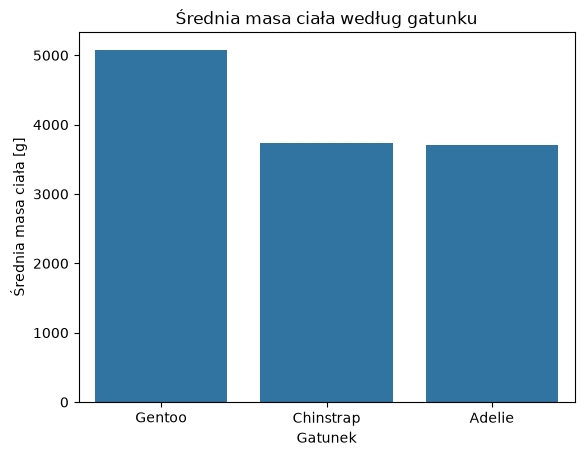

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df, x="species", y="avg_mass")
plt.xlabel("Gatunek")
plt.ylabel("Średnia masa ciała [g]")
plt.title("Średnia masa ciała według gatunku")
plt.savefig("img/cw7_avg_mass.png", dpi=150, bbox_inches="tight")
plt.show()

## Ćwiczenie samodzielne nr 3 – długość płetwy wg gatunku i płci

Wybrano zapytanie agregacyjne z ćwiczenia samodzielnego 2 (2): średnia, minimalna i maksymalna długość płetwy dla par gatunek–płeć (bez węzłów z brakiem płci).

In [4]:
query_flipper = """
MATCH (p:Penguin)-[:OF_SPECIES]->(s:Species)
WHERE p.sex IS NOT NULL
RETURN s.name AS species, p.sex AS sex,
       round(avg(p.flipper_length_mm), 2) AS avg_flipper,
       min(p.flipper_length_mm) AS min_flipper,
       max(p.flipper_length_mm) AS max_flipper,
       count(p) AS cnt
ORDER BY species, sex
"""
df_f = driver.execute_query(query_flipper, result_transformer_=Result.to_df)
df_f

,species,sex,avg_flipper,min_flipper,max_flipper,cnt
0,Adelie,female,187.79,172,202,73
1,Adelie,male,192.41,178,210,73
2,Chinstrap,female,191.74,178,202,34
3,Chinstrap,male,199.91,187,212,34
4,Gentoo,female,212.71,203,222,58
5,Gentoo,male,221.54,208,231,61


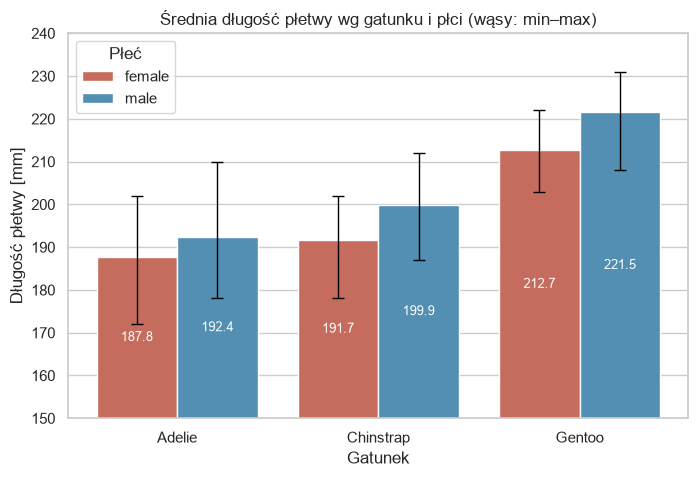

In [5]:
import numpy as np

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_f, x="species", y="avg_flipper", hue="sex",
            palette={"female": "#d6604d", "male": "#4393c3"}, ax=ax)
# zakres min–max jako "wąsy" nad słupkami
n_hue = df_f["sex"].nunique()
for bar_container, sex in zip(ax.containers, ["female", "male"]):
    sub = df_f[df_f["sex"] == sex].set_index("species").loc[[t.get_text() for t in ax.get_xticklabels()]]
    for bar, (_, row) in zip(bar_container, sub.iterrows()):
        x = bar.get_x() + bar.get_width() / 2
        ax.errorbar(x, row.avg_flipper,
                    yerr=[[row.avg_flipper - row.min_flipper], [row.max_flipper - row.avg_flipper]],
                    fmt="none", ecolor="black", capsize=4, lw=1)
    ax.bar_label(bar_container, fmt="%.1f", label_type="center", color="white", fontsize=9)
ax.set_ylim(150, 240)
ax.set_xlabel("Gatunek")
ax.set_ylabel("Długość płetwy [mm]")
ax.set_title("Średnia długość płetwy wg gatunku i płci (wąsy: min–max)")
ax.legend(title="Płeć", labels=None)
plt.savefig("img/samodz3_flipper.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretacja.** Gentoo ma wyraźnie najdłuższe płetwy (średnio ok. 213 mm u samic i 222 mm u samców), o ponad 20 mm więcej niż Adelie i Chinstrap, których zakresy w dużej mierze się pokrywają. W każdym gatunku samce mają dłuższe płetwy od samic (różnica ok. 5–9 mm), co potwierdza dymorfizm płciowy. Długość płetwy jest więc dobrą cechą do odróżnienia Gentoo od pozostałych gatunków, ale słabo rozdziela Adelie i Chinstrap.

## Dodatkowo – trend średniej masy w latach (ćw. samodzielne 2 (3))

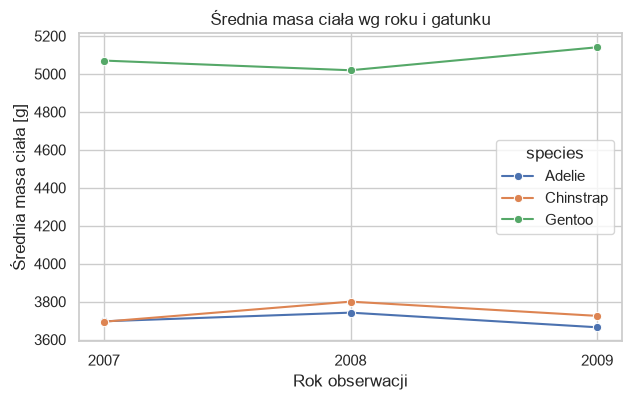

In [6]:
query_year = """
MATCH (p:Penguin)-[:OF_SPECIES]->(s:Species)
RETURN s.name AS species, p.year AS year,
       round(avg(p.body_mass_g), 2) AS avg_mass
ORDER BY species, year
"""
df_y = driver.execute_query(query_year, result_transformer_=Result.to_df)
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=df_y, x="year", y="avg_mass", hue="species", marker="o", ax=ax)
ax.set_xticks([2007, 2008, 2009])
ax.set_xlabel("Rok obserwacji")
ax.set_ylabel("Średnia masa ciała [g]")
ax.set_title("Średnia masa ciała wg roku i gatunku")
plt.savefig("img/samodz2_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
driver.close()